# 06 – Filter Comparison

** | Tích hợp và đánh giá kết quả**

## Mục tiêu
- So sánh Mean, Gaussian, Median, Bilateral, Sharpening, Sobel và Prewitt trên cùng một ảnh.
- Hiển thị kết quả trực quan, đo thời gian chạy và tính PSNR/SSIM khi phù hợp.
- Lưu hình so sánh và bảng kết quả vào thư mục dự án.

> Notebook sử dụng các hàm có sẵn trong `src/`, không thay thế thuật toán của thành viên khác.

## 1. Khởi tạo đường dẫn và thư viện
Chạy notebook từ thư mục `lab_2` hoặc `lab_2/notebook`. Nếu cấu trúc khác, chỉnh `ROOT` cho đúng thư mục gốc dự án.

In [1]:
from pathlib import Path
import sys
import cv2
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
if not ((ROOT / "src").is_dir() and (ROOT / "data" / "input").is_dir()):
    for candidate in (Path.cwd().parent, Path.cwd().parent.parent):
        if (candidate / "src").is_dir() and (candidate / "data" / "input").is_dir():
            ROOT = candidate
            break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
INPUT_DIR = ROOT / "data" / "input"
FIGURE_DIR = ROOT / "result" / "figures"
OUTPUT_DIR = ROOT / "data" / "output"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Input folder exists:", INPUT_DIR.is_dir())

Project root: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2
Input folder exists: True


## 2. Import hàm của nhóm
Nếu cell báo lỗi import, kiểm tra tên hàm trong module tương ứng; không cần sửa thuật toán.

In [2]:
from src.common import read_image, bgr_to_rgb
from src.blur_filters import apply_mean_filter, apply_gaussian_filter, calculate_psnr, calculate_ssim
from src.sharpen_custom import sharpen_image
from src.nonlinear_filters import median_filter, apply_bilateral_filter
from src.edge_detection import sobel_edges, prewitt_edges
from src.evaluation import measure_runtime
print("Import thành công.")

Import thành công.


## 3. Chọn ảnh đầu vào
Mặc định dùng ảnh đầu tiên trong `data/input`. Có thể đặt `IMAGE_NAME` thành tên ảnh cụ thể.

Ảnh đang dùng: 01_astronaut.png
Kích thước: (512, 512, 3)


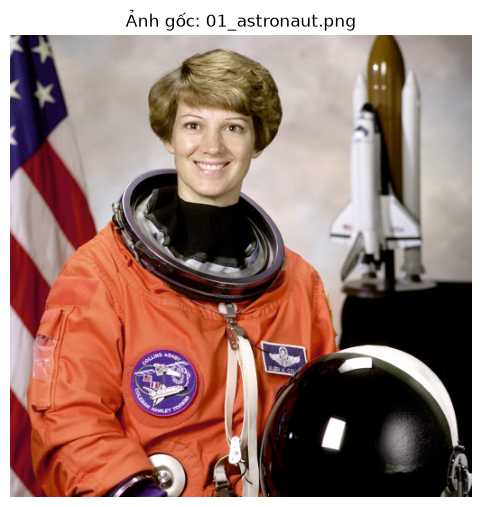

In [3]:
IMAGE_NAME = None  # Ví dụ: "01_astronaut.png"
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
image_files = sorted(p for p in INPUT_DIR.iterdir() if p.is_file() and p.suffix.lower() in valid_extensions)
if not image_files:
    raise FileNotFoundError(f"Không tìm thấy ảnh trong {INPUT_DIR}; hãy đặt ảnh vào data/input.")
if IMAGE_NAME:
    matches = [p for p in image_files if p.name == IMAGE_NAME]
    if not matches:
        raise FileNotFoundError(f"Không tìm thấy {IMAGE_NAME} trong {INPUT_DIR}")
    image_path = matches[0]
else:
    image_path = image_files[0]
image = read_image(image_path)
print("Ảnh đang dùng:", image_path.name)
print("Kích thước:", image.shape)
plt.figure(figsize=(6, 6))
plt.imshow(bgr_to_rgb(image))
plt.title(f"Ảnh gốc: {image_path.name}")
plt.axis("off")
plt.show()

## 4. Chạy các bộ lọc
Các hàm lọc cơ bản được gọi theo cách đã kiểm tra. Với Sharpening, Sobel và Prewitt, notebook thử gọi ảnh đầu vào trực tiếp, rồi thử truyền các tham số phổ biến nếu chữ ký hàm yêu cầu.

In [4]:
def flexible_call(function, img):
    signature = inspect.signature(function)
    params = list(signature.parameters.values())
    if not params:
        return function()
    kwargs = {}
    values = {
        "ksize": 5, "kernel_size": 5, "k_size": 5,
        "amount": 1.0, "alpha": 1.0, "strength": 1.0,
        "threshold": 0, "low_threshold": 100, "high_threshold": 200,
        "sigma": 1.0, "sigma_x": 1.0, "sigma_y": 1.0,
        "d": 9, "sigma_color": 75, "sigma_space": 75,
    }
    for p in params[1:]:
        if p.name in values and p.default is not inspect.Parameter.empty:
            kwargs[p.name] = values[p.name]
    try:
        return function(img.copy(), **kwargs)
    except TypeError:
        return function(img.copy())

methods = {
    "Mean Filter": lambda img: apply_mean_filter(img, 5),
    "Gaussian Filter": lambda img: apply_gaussian_filter(img, 5),
    "Median Filter": lambda img: median_filter(img, 5),
    "Bilateral Filter": lambda img: apply_bilateral_filter(img),
    "Sharpening": lambda img: flexible_call(sharpen_image, img),
    "Sobel Edges": lambda img: flexible_call(sobel_edges, img),
    "Prewitt Edges": lambda img: flexible_call(prewitt_edges, img),
}
outputs, errors = {}, {}
for name, function in methods.items():
    try:
        result = np.asarray(function(image.copy()))
        if result.size == 0:
            raise ValueError("Kết quả ảnh rỗng")
        outputs[name] = result
        print(f"{name}: OK — shape {result.shape}, dtype {result.dtype}")
    except Exception as exc:
        errors[name] = f"{type(exc).__name__}: {exc}"
        print(f"{name}: LỖI — {errors[name]}")

Mean Filter: OK — shape (512, 512, 3), dtype uint8
Gaussian Filter: OK — shape (512, 512, 3), dtype uint8
Median Filter: OK — shape (512, 512, 3), dtype uint8
Bilateral Filter: OK — shape (512, 512, 3), dtype uint8
Sharpening: OK — shape (512, 512, 3), dtype uint8
Sobel Edges: OK — shape (3, 512, 512), dtype float32
Prewitt Edges: OK — shape (3, 512, 512), dtype float32


## 5. Hiển thị và lưu ảnh so sánh
Ảnh gốc và các kết quả thành công sẽ được hiển thị cùng nhau.

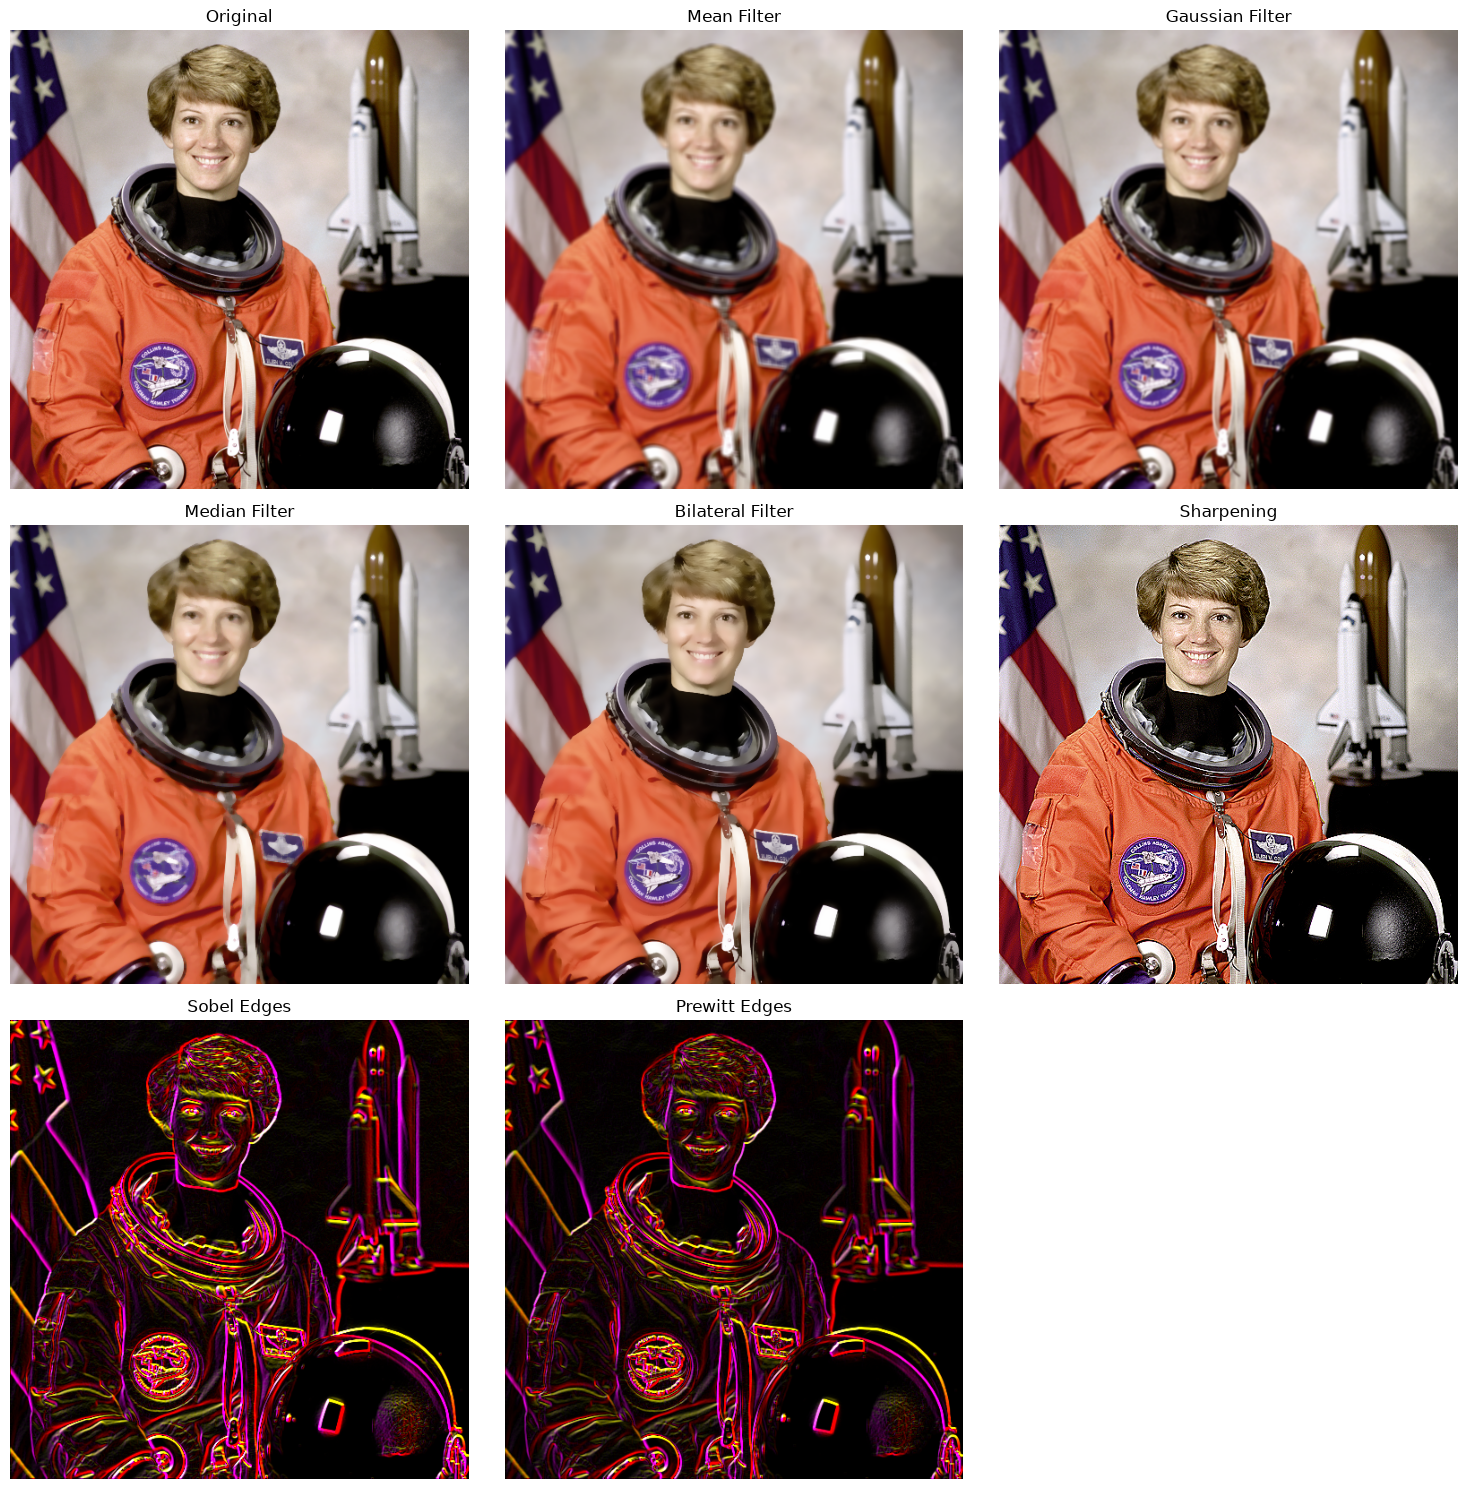

In [5]:

def plot_ready(img):
    img = np.asarray(img)

    # Chuyển ảnh từ CHW (C, H, W) sang HWC (H, W, C)
    if img.ndim == 3 and img.shape[0] in (1, 3, 4) and img.shape[-1] not in (1, 3, 4):
        img = np.transpose(img, (1, 2, 0))

    # Ảnh một kênh màu: chuyển thành ảnh 2D
    if img.ndim == 3 and img.shape[-1] == 1:
        img = img[:, :, 0]

    # Ảnh màu OpenCV: BGR -> RGB
    if img.ndim == 3 and img.shape[-1] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Chuẩn hóa kiểu dữ liệu nếu đầu ra là float
    if np.issubdtype(img.dtype, np.floating):
        img = np.nan_to_num(img)

        if img.min() >= 0 and img.max() <= 1:
            img = np.clip(img, 0, 1)
        else:
            img = np.clip(img, 0, 255).astype(np.uint8)

    return img, "gray" if img.ndim == 2 else None


items = [("Original", image)] + list(outputs.items())

n = len(items)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = np.asarray(axes).reshape(-1)

for ax, (name, img) in zip(axes, items):
    shown, cmap = plot_ready(img)
    ax.imshow(shown, cmap=cmap)
    ax.set_title(name)
    ax.axis("off")

for ax in axes[len(items):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Đo thời gian chạy
Mỗi phương pháp chạy nhiều lần trên bản sao của ảnh gốc. Đơn vị là millisecond.

,Method,Average time (ms),Min time (ms),Max time (ms)
0,Mean Filter,2.008,1.735,2.414
1,Gaussian Filter,0.767,0.526,1.153
2,Median Filter,2.484,2.279,2.663
3,Bilateral Filter,37.266,32.213,41.057
4,Sharpening,0.899,0.713,1.021
5,Sobel Edges,4.015,3.733,4.297
6,Prewitt Edges,5.243,4.495,5.835


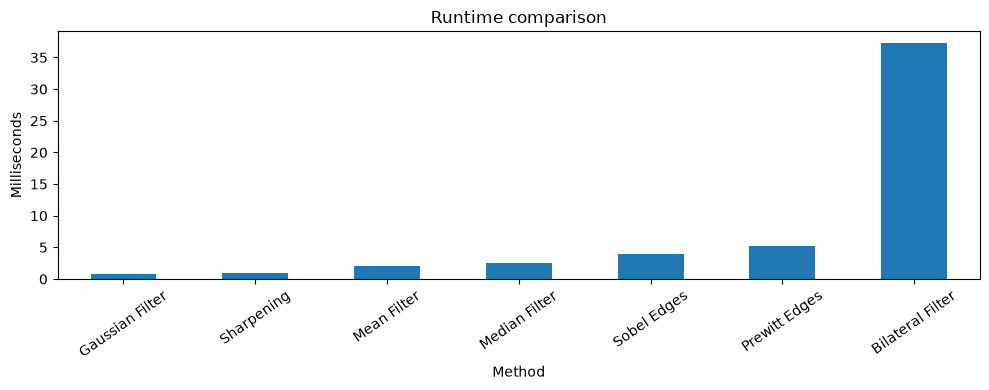

Đã lưu: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\result\figures\06_runtime_comparison.png


In [6]:
REPEATS = 3
timing_rows = []
for name, function in methods.items():
    if name not in outputs:
        continue
    try:
        measured = measure_runtime(function, image.copy(), repeats=REPEATS)
        timing_rows.append({
            "Method": name,
            "Average time (ms)": round(measured["average_time_ms"], 3),
            "Min time (ms)": round(measured["min_time_ms"], 3),
            "Max time (ms)": round(measured["max_time_ms"], 3),
        })
    except Exception as exc:
        print(f"Không đo được {name}: {type(exc).__name__}: {exc}")
timing_df = pd.DataFrame(timing_rows)
display(timing_df)
if not timing_df.empty:
    ax = timing_df.sort_values("Average time (ms)").plot(
        x="Method", y="Average time (ms)", kind="bar", legend=False,
        figsize=(10, 4), rot=35
    )
    ax.set_ylabel("Milliseconds")
    ax.set_title("Runtime comparison")
    plt.tight_layout()
    runtime_path = FIGURE_DIR / "06_runtime_comparison.png"
    plt.savefig(runtime_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Đã lưu:", runtime_path)

## 7. PSNR và SSIM
Các chỉ số này được tính khi kết quả có cùng kích thước với ảnh gốc. Với Sobel/Prewitt, chỉ số so với ảnh gốc không phải thước đo chất lượng phát hiện cạnh, nên cần diễn giải thận trọng.

In [7]:
quality_rows = []
for name, result in outputs.items():
    row = {"Method": name, "PSNR (dB)": np.nan, "SSIM": np.nan}
    if result.shape == image.shape:
        try:
            row["PSNR (dB)"] = calculate_psnr(image, result)
        except Exception:
            pass
        try:
            row["SSIM"] = calculate_ssim(image, result)
        except Exception:
            pass
    quality_rows.append(row)
quality_df = pd.DataFrame(quality_rows)
display(quality_df.round(4))

,Method,PSNR (dB),SSIM
0,Mean Filter,26.0710,0.8564
1,Gaussian Filter,29.3024,0.9281
2,Median Filter,28.1508,0.9012
3,Bilateral Filter,33.4346,0.9348
4,Sharpening,21.8242,0.7567
5,Sobel Edges,NaN,NaN
6,Prewitt Edges,NaN,NaN


## 8. Lưu bảng và lỗi (nếu có)

In [8]:
if not timing_df.empty:
    timing_csv = OUTPUT_DIR / "06_runtime_comparison.csv"
    timing_df.to_csv(timing_csv, index=False)
    print("Đã lưu:", timing_csv)
if not quality_df.empty:
    quality_csv = OUTPUT_DIR / "06_quality_metrics.csv"
    quality_df.to_csv(quality_csv, index=False)
    print("Đã lưu:", quality_csv)
if errors:
    error_df = pd.DataFrame([{"Method": k, "Error": v} for k, v in errors.items()])
    error_csv = OUTPUT_DIR / "06_method_errors.csv"
    error_df.to_csv(error_csv, index=False)
    print("Một số phương pháp lỗi; đã lưu chi tiết:", error_csv)
print(f"Hoàn tất: {len(outputs)}/{len(methods)} phương pháp chạy thành công.")

Đã lưu: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\data\output\06_runtime_comparison.csv
Đã lưu: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_2\data\output\06_quality_metrics.csv
Hoàn tất: 7/7 phương pháp chạy thành công.


## 9. Nhận xét thực nghiệm
- **Mean Filter:** đơn giản, giảm nhiễu nhưng có thể làm mờ cạnh.
- **Gaussian Filter:** làm mượt theo trọng số Gaussian; vẫn có thể làm mờ chi tiết.
- **Median Filter:** thường hiệu quả với nhiễu muối tiêu và giữ cạnh tốt hơn bộ lọc trung bình.
- **Bilateral Filter:** làm mượt trong khi thường giữ cạnh tốt, nhưng có thể chậm hơn.
- **Sharpening:** tăng độ nổi bật chi tiết/cạnh; quá mạnh có thể làm nhiễu rõ hơn.
- **Sobel và Prewitt:** làm nổi bật vùng thay đổi cường độ để phát hiện cạnh; kết quả là bản đồ cạnh chứ không phải ảnh khử nhiễu.

Kết luận cuối cùng cần dựa trên ảnh và số đo thực tế. Không có bộ lọc nào tốt nhất cho mọi loại ảnh.